# KHAI PHÁ DỮ LIỆU - LAB 2
### Sinh viên: Ngô Minh Khôi
### MSSV: 6451071037


## Câu 3: Khảo sát độ tương đồng giữa các cột với nhau bằng công thức Pearson
Kết hợp với thư viện seaborn để trực quan hóa kết quả bằng đồ thị heatmap.

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Kích thước dữ liệu Red Wine: (1599, 12)
Thông tin dữ liệu:

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


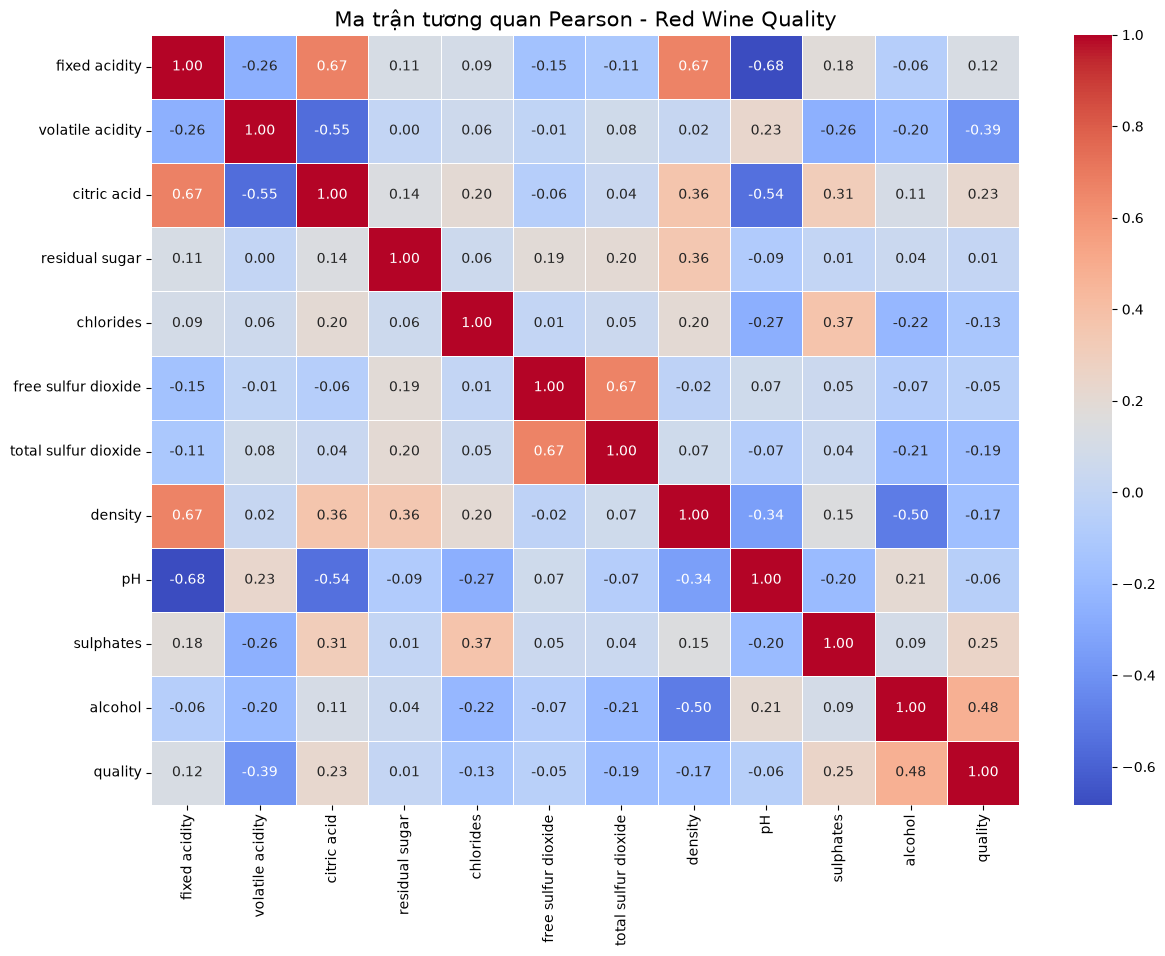

Nhận xét: Không có cặp thuộc tính nào có tương quan quá cao (tất cả |r| < 0.7), nên ta giữ lại toàn bộ các thuộc tính cho bài toán.


In [1]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu Red Wine Quality
wine_df = pd.read_csv('datasets/winequality-red.csv')
print("Kích thước dữ liệu Red Wine:", wine_df.shape)
print("Thông tin dữ liệu:\n")
wine_df.info()

plt.figure(figsize=(14, 10))
sns.heatmap(wine_df.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', linewidths=.5)
plt.title("Ma trận tương quan Pearson - Red Wine Quality", fontsize=15)
plt.show()

print("Nhận xét: Không có cặp thuộc tính nào có tương quan quá cao (tất cả |r| < 0.7), nên ta giữ lại toàn bộ các thuộc tính cho bài toán.")


## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)
Lưu ý: Thuộc tính quyết định là 'quality'.

In [2]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
features = wine_df.drop('quality', axis=1)
labels = wine_df['quality']

print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("Phân phối giá trị thuộc tính quyết định 'quality':")
print(labels.value_counts().sort_index())


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước features: (1599, 11)
Kích thước labels: (1599,)
Phân phối giá trị thuộc tính quyết định 'quality':
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [3]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
non_num = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các cột không phải dạng số:", list(non_num))
if len(non_num) == 0:
    print("Tất cả các thuộc tính của Red Wine đều đã ở dạng số thực, do đó không cần thực hiện One-Hot Encoding.")
    features_onehot = features.copy()
else:
    features_onehot = pd.get_dummies(features, columns=non_num)
print("Kích thước features sau xử lý:", features_onehot.shape)


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Các cột không phải dạng số: []
Tất cả các thuộc tính của Red Wine đều đã ở dạng số thực, do đó không cần thực hiện One-Hot Encoding.
Kích thước features sau xử lý: (1599, 11)


## Câu 6: Chia dữ liệu đầu vào thành hai phần huấn luyện 70% và kiểm thử 30%
`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)`

In [4]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

print(f"Tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Tập huấn luyện X_train: (1119, 11), y_train: (1119,)
Tập kiểm thử X_test: (480, 11), y_test: (480,)


## Câu 7: Xây dựng cây ID3 (criterion='entropy') và kiểm thử kết quả bằng ma trận nhầm lẫn

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Decision Tree (ID3) Accuracy: 0.5833
Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



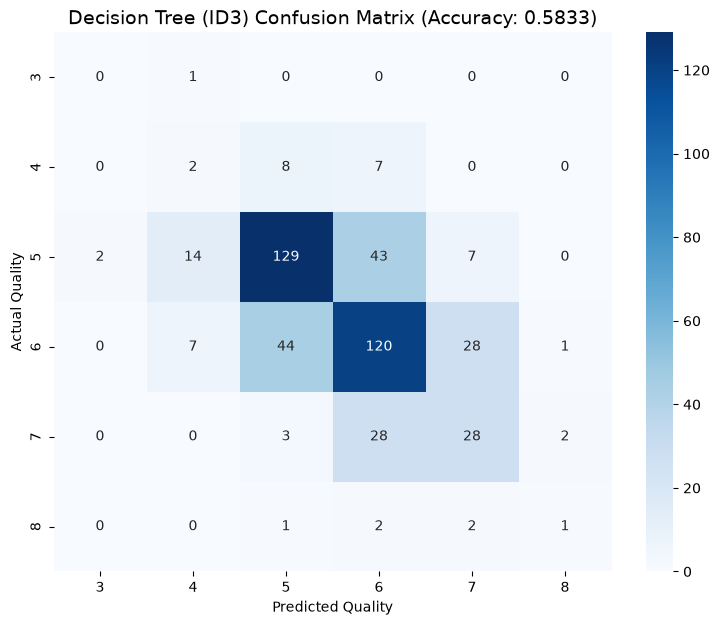

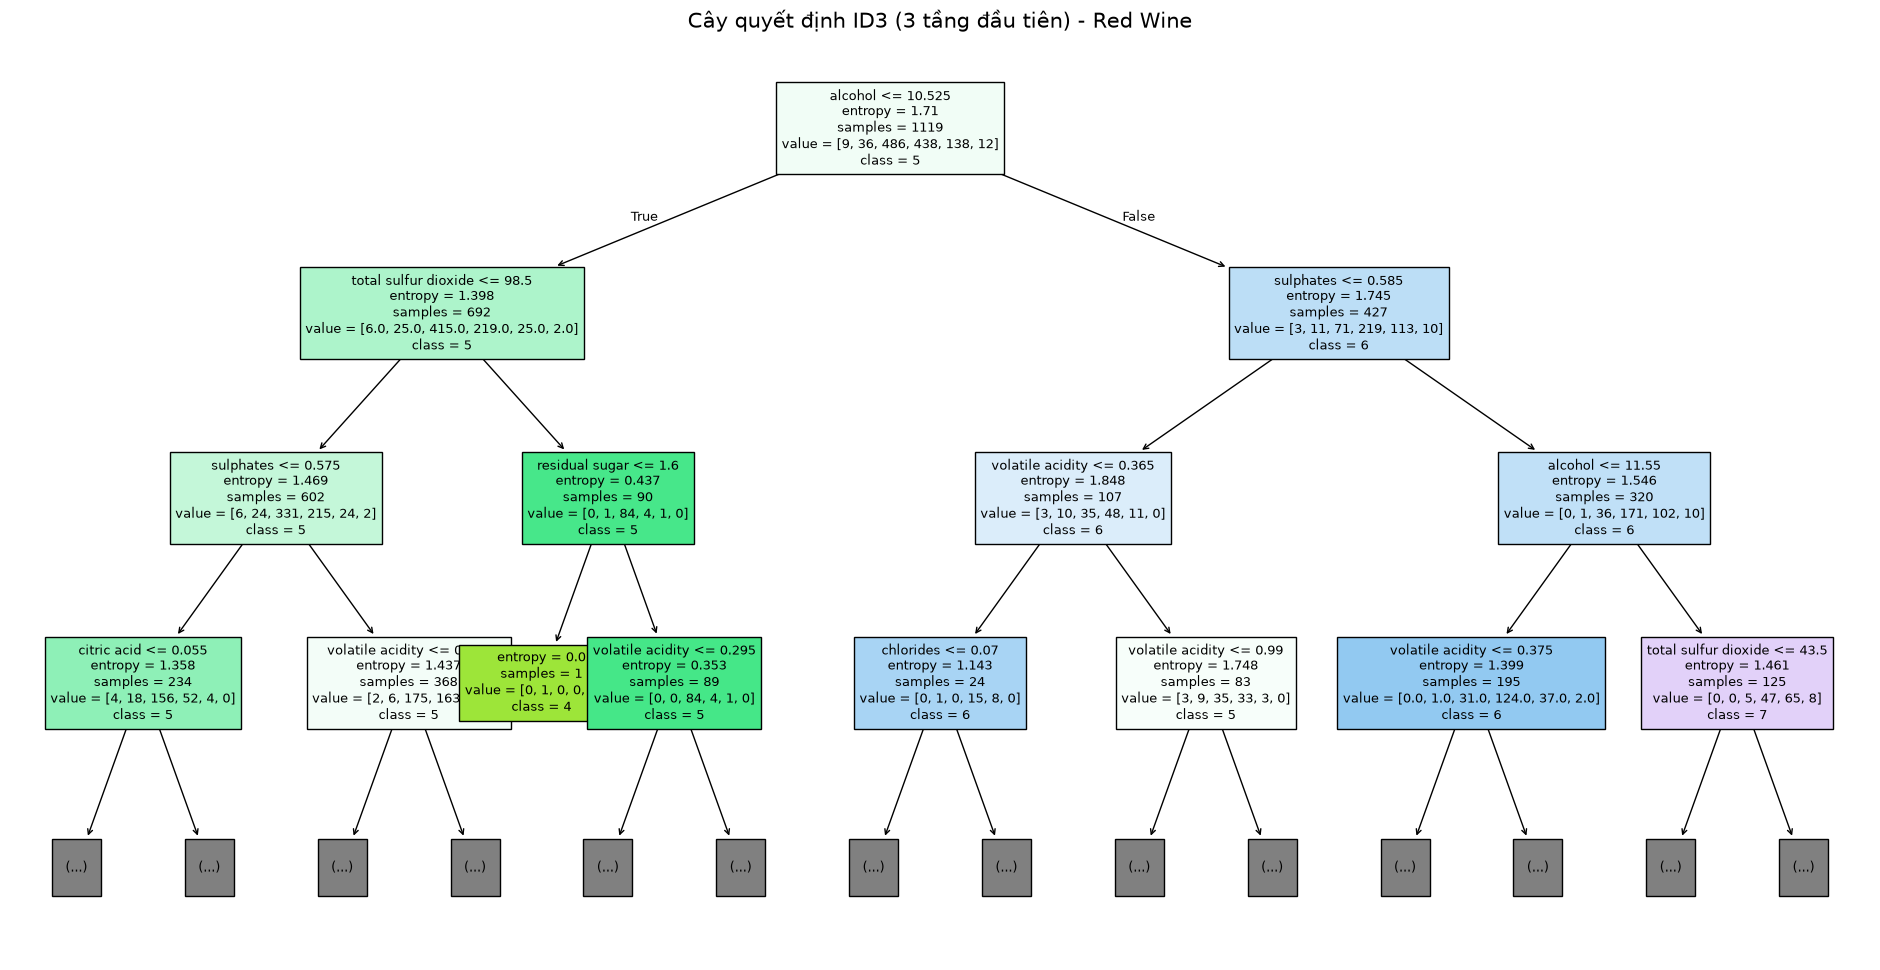

In [5]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn import tree, metrics

clf_id3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)
clf_id3.fit(X_train, y_train)

tree_pred = clf_id3.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)
print(f"Decision Tree (ID3) Accuracy: {tree_score:.4f}")
print("Classification Report:\n", metrics.classification_report(y_test, tree_pred, zero_division=0))

# Ma trận nhầm lẫn
tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(tree_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(labels), yticklabels=np.unique(labels))
plt.ylabel('Actual Quality')
plt.xlabel('Predicted Quality')
plt.title(f'Decision Tree (ID3) Confusion Matrix (Accuracy: {tree_score:.4f})', fontsize=14)
plt.show()

# Biểu diễn cây
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf_id3, max_depth=3, feature_names=features.columns, class_names=[str(c) for c in np.unique(labels)], filled=True, fontsize=9)
plt.title("Cây quyết định ID3 (3 tầng đầu tiên) - Red Wine", fontsize=15)
plt.savefig('decision_tree_id3_wine.png', dpi=100)
plt.show()


## Câu 8: Lặp lại yêu cầu 7 đối với cây CART (criterion='gini')

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Decision Tree (CART) Accuracy: 0.5625
Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



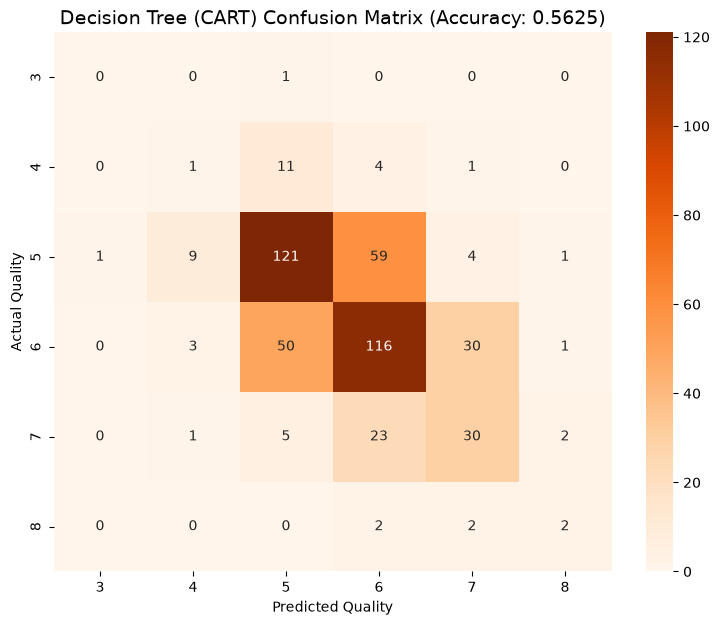

In [6]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
clf_cart = tree.DecisionTreeClassifier(criterion='gini', random_state=0)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"Decision Tree (CART) Accuracy: {cart_score:.4f}")
print("Classification Report:\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

# Ma trận nhầm lẫn CART
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cart_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=np.unique(labels), yticklabels=np.unique(labels))
plt.ylabel('Actual Quality')
plt.xlabel('Predicted Quality')
plt.title(f'Decision Tree (CART) Confusion Matrix (Accuracy: {cart_score:.4f})', fontsize=14)
plt.show()


## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Naïve Bayes Accuracy: 0.5417
Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



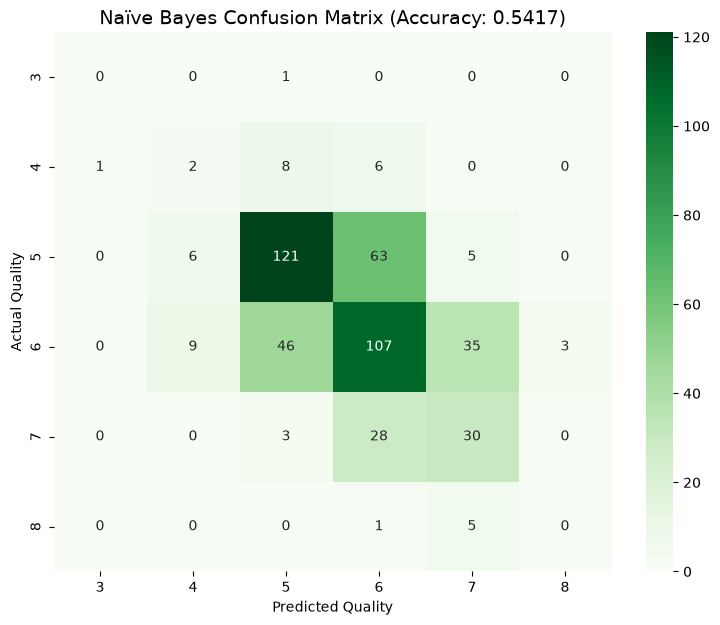

In [7]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

bayes_pred = gnb.predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"Naïve Bayes Accuracy: {bayes_score:.4f}")
print("Classification Report:\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(bayes_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=np.unique(labels), yticklabels=np.unique(labels))
plt.ylabel('Actual Quality')
plt.xlabel('Predicted Quality')
plt.title(f'Naïve Bayes Confusion Matrix (Accuracy: {bayes_score:.4f})', fontsize=14)
plt.show()


## Câu 10: So sánh kết quả của các mô hình trên

In [8]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
compare_wine = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3 - Entropy)', 'Decision Tree (CART - Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [
        metrics.accuracy_score(y_test, tree_pred),
        metrics.accuracy_score(y_test, cart_pred),
        metrics.accuracy_score(y_test, bayes_pred)
    ],
    'Precision (Weighted)': [
        metrics.precision_score(y_test, tree_pred, average='weighted', zero_division=0),
        metrics.precision_score(y_test, cart_pred, average='weighted', zero_division=0),
        metrics.precision_score(y_test, bayes_pred, average='weighted', zero_division=0)
    ],
    'Recall (Weighted)': [
        metrics.recall_score(y_test, tree_pred, average='weighted', zero_division=0),
        metrics.recall_score(y_test, cart_pred, average='weighted', zero_division=0),
        metrics.recall_score(y_test, bayes_pred, average='weighted', zero_division=0)
    ],
    'F1-Score (Weighted)': [
        metrics.f1_score(y_test, tree_pred, average='weighted', zero_division=0),
        metrics.f1_score(y_test, cart_pred, average='weighted', zero_division=0),
        metrics.f1_score(y_test, bayes_pred, average='weighted', zero_division=0)
    ]
})

print("BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP DỮ LIỆU RED WINE QUALITY:")
display(compare_wine)

print("\n--- NHẬN XÉT CHI TIẾT ---")
print("1. Cây quyết định CART (Gini) và ID3 (Entropy) đều đạt độ chính xác khá tốt trên bài toán phân lớp chất lượng rượu đa lớp (6 mức chất lượng từ 3 đến 8).")
print("2. Thuật toán Naïve Bayes có độ chính xác thấp hơn (~54%) do thuộc tính chất lượng rượu vang có sự tương tác và tương quan hóa lý phức tạp, vi phạm giả định độc lập có điều kiện của Naïve Bayes.")
print("3. Điểm F1-Score của Cây quyết định cao hơn rõ rệt so với Naïve Bayes trên tập dữ liệu này.")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP DỮ LIỆU RED WINE QUALITY:


,Mô hình,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Decision Tree (ID3 - Entropy),0.583333,0.594097,0.583333,0.588259
1,Decision Tree (CART - Gini),0.562500,0.561997,0.562500,0.561986
2,Naïve Bayes (GaussianNB),0.541667,0.547096,0.541667,0.543265



--- NHẬN XÉT CHI TIẾT ---
1. Cây quyết định CART (Gini) và ID3 (Entropy) đều đạt độ chính xác khá tốt trên bài toán phân lớp chất lượng rượu đa lớp (6 mức chất lượng từ 3 đến 8).
2. Thuật toán Naïve Bayes có độ chính xác thấp hơn (~54%) do thuộc tính chất lượng rượu vang có sự tương tác và tương quan hóa lý phức tạp, vi phạm giả định độc lập có điều kiện của Naïve Bayes.
3. Điểm F1-Score của Cây quyết định cao hơn rõ rệt so với Naïve Bayes trên tập dữ liệu này.
